# Quimil — limpeza e entrega da silver

Preparamos as duas fontes separadas, preservando o histórico e a resolução original.
Cada tratamento segue **evidência → motivo → aplicação → conferência**.
O [notebook 02](02-gold-abt.ipynb) prepara a tabela para ML a partir desta silver.

A potência está em W. Vento em m/s e umidade em % são convenções de trabalho.
Os arquivos não informam fuso; mantemos os horários registrados.


## 1. Leitura e qualidade das chaves

Lemos os quatro arquivos, concatenamos os anos e convertemos `timestamp` para data.
A conversão usa `errors="raise"`: uma data não interpretável aparece como erro de leitura.
Os arquivos raw permanecem intactos.


In [1]:
from datetime import UTC, datetime
import json
from pathlib import Path
import warnings

from IPython.display import display
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = next(
    path
    for path in (Path.cwd(), *Path.cwd().parents)
    if (path / "pyproject.toml").is_file() and (path / "data" / "raw").is_dir()
)
RAW_DIR = ROOT / "data" / "raw"
SILVER_DIR = ROOT / "data" / "silver"
FIGURES_DIR = ROOT / "reports" / "figures" / "eda" / "primeiro-contato"
SILVER_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

pd.set_option("display.max_columns", 20)
pd.set_option("display.max_rows", 30)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
%matplotlib inline

In [2]:
# A leitura é repetida apenas para os dois anos; não há filtros nas medições.
raw_sources = {}
file_records = []
for source, prefix in [("inversor", "Quimil-inversor"), ("meteorologia", "LABCHECAP")]:
    parts = []
    for year in (2025, 2026):
        suffix = ".csv" if source == "inversor" else ".xlsx"
        filename = f"{prefix}-{year}{suffix}"
        with warnings.catch_warnings():
            warnings.filterwarnings("ignore", message="Workbook contains no default style")
            frame = (
                pd.read_csv(RAW_DIR / filename)
                if suffix == ".csv"
                else pd.read_excel(RAW_DIR / filename, sheet_name=0)
            )
        frame["timestamp"] = pd.to_datetime(frame["timestamp"], format="mixed", errors="raise")
        file_records.append({"arquivo": filename, "linhas": len(frame), "colunas": frame.shape[1]})
        parts.append(frame)
    raw_sources[source] = pd.concat(parts, ignore_index=True)

display(pd.DataFrame(file_records))

,arquivo,linhas,colunas
0,Quimil-inversor-2025.csv,54150,55
1,Quimil-inversor-2026.csv,28654,55
2,LABCHECAP-2025.xlsx,104770,10
3,LABCHECAP-2026.xlsx,77359,10


In [3]:
key_records = []
for source, frame in raw_sources.items():
    device = "ps_key" if source == "inversor" else "device"
    key_records.append(
        {
            "fonte": source,
            "equipamentos": frame[device].nunique(dropna=True),
            "IDs_ausentes": int(frame[device].isna().sum()),
            "datas_ausentes": int(frame["timestamp"].isna().sum()),
            "timestamps_duplicados": int(frame["timestamp"].duplicated().sum()),
            "linhas_duplicadas": int(frame.duplicated().sum()),
        }
    )
key_audit = pd.DataFrame(key_records)
display(key_audit)

,fonte,equipamentos,IDs_ausentes,datas_ausentes,timestamps_duplicados,linhas_duplicadas
0,inversor,1,0,0,0,0
1,meteorologia,1,0,0,0,0


**O que vimos:** há um equipamento por fonte, nenhuma data ausente e nenhuma duplicação.
As datas dos arquivos atuais foram interpretadas sem erros. Não precisamos deduplicar linhas.
Podemos retirar os identificadores depois dessa conferência, mantendo `timestamp` como chave.


## 2. Tipos, nulos e colunas sem uso

Contamos os nulos nos dois anos juntos e distinguimos medições de textos e identificadores.
A tabela resume os tipos encontrados e as regras que serão aplicadas. Os nomes de todas as
colunas removidas serão registrados nos metadados da entrega.


In [4]:
audit_parts = []
for source, frame in raw_sources.items():
    audit = pd.DataFrame(
        {
            "fonte": source,
            "coluna": frame.columns,
            "tipo": frame.dtypes.astype(str).to_numpy(),
            "nulos": frame.isna().sum().to_numpy(),
            "linhas": len(frame),
        }
    )
    textual = frame.select_dtypes(include=["object", "string", "category"]).columns
    audit["regra"] = np.select(
        [
            audit["nulos"].eq(len(frame)),
            audit["coluna"].isin(textual),
            audit["coluna"].eq("ps_id"),
        ],
        ["remover: 100% nula", "remover: textual/identificador", "remover: ID numérico"],
        default="preservar",
    )
    audit_parts.append(audit)
column_audit = pd.concat(audit_parts, ignore_index=True)
column_summary = (
    column_audit.groupby(["fonte", "tipo", "regra"], sort=False)
    .agg(colunas=("coluna", "size"), celulas_nulas=("nulos", "sum"))
    .reset_index()
)
display(column_summary)

,fonte,tipo,regra,colunas,celulas_nulas
0,inversor,object,remover: textual/identificador,3,0
1,inversor,int64,remover: ID numérico,1,0
2,inversor,datetime64[ns],preservar,1,0
3,inversor,int64,preservar,3,0
4,inversor,float64,remover: 100% nula,36,2980944
5,inversor,float64,preservar,11,0
6,meteorologia,object,remover: textual/identificador,1,0
7,meteorologia,datetime64[ns],preservar,1,0
8,meteorologia,float64,preservar,4,0
9,meteorologia,float64,remover: 100% nula,4,728516


**Decisão e motivo:** retiramos colunas 100% nulas, textos e identificadores, incluindo
`ps_id`. Campos sem medições não contribuem para a análise; os identificadores não distinguem
múltiplos equipamentos nesta base. `timestamp` já é datetime e permanece.

Medições numéricas parcialmente preenchidas continuam. **Zero é uma observação, não um nulo.**
Não excluímos linhas nem preenchemos medições ausentes nesta etapa.


In [5]:
removed_columns = column_audit.loc[column_audit["regra"].ne("preservar")].copy()
removed_columns["motivo"] = removed_columns["regra"].str.removeprefix("remover: ")
cleaned_sources = {}
for source, frame in raw_sources.items():
    removed = removed_columns.loc[removed_columns["fonte"].eq(source), "coluna"]
    cleaned_sources[source] = (
        frame.drop(columns=removed.tolist()).sort_values("timestamp").reset_index(drop=True).copy()
    )
inverter = cleaned_sources["inversor"]
weather = cleaned_sources["meteorologia"]

structural_check = pd.DataFrame(
    [
        {
            "fonte": source,
            "linhas_antes": len(raw_sources[source]),
            "linhas_depois": len(frame),
            "colunas_antes": raw_sources[source].shape[1],
            "colunas_depois": frame.shape[1],
            "celulas_nulas_restantes": int(frame.isna().sum().sum()),
        }
        for source, frame in cleaned_sources.items()
    ]
)
display(structural_check)

,fonte,linhas_antes,linhas_depois,colunas_antes,colunas_depois,celulas_nulas_restantes
0,inversor,82804,82804,55,15,0
1,meteorologia,182129,182129,10,5,0


In [6]:
# A estrutura restante também documenta os tipos que serão preservados pelo Parquet.
remaining_schema = pd.concat(
    [
        pd.DataFrame(
            {
                "fonte": source,
                "coluna": frame.columns,
                "tipo": frame.dtypes.astype(str).to_numpy(),
                "nulos": frame.isna().sum().to_numpy(),
            }
        )
        for source, frame in cleaned_sources.items()
    ],
    ignore_index=True,
)
display(remaining_schema)

,fonte,coluna,tipo,nulos
0,inversor,timestamp,datetime64[ns],0
1,inversor,total_active_power,int64,0
2,inversor,total_dc_power,int64,0
3,inversor,phase_a_current,float64,0
4,inversor,phase_b_current,float64,0
5,inversor,phase_c_current,float64,0
6,inversor,array_insulation_resistance,int64,0
7,inversor,internal_air_temperature,float64,0
8,inversor,mppt1_voltage,float64,0
9,inversor,mppt2_voltage,float64,0


## 3. Vento: o que significam os pequenos valores negativos?

**Evidência:** os negativos são somente `−0,018` e `−0,036`, totalizando 20.513 leituras.
As próximas tabelas mostram suas frequências, uma amostra e a distribuição completa.
A causa no sensor não foi confirmada.


In [7]:
weather_before_wind = weather.copy(deep=True)
negative_mask = weather["wind_speed"].lt(0)
negative_wind = weather.loc[negative_mask, "wind_speed"]
negative_frequency = (
    negative_wind.value_counts().rename_axis("vento_m_s").reset_index(name="leituras")
)
negative_frequency["pct_meteorologia"] = negative_frequency["leituras"] / len(weather) * 100
display(negative_frequency.round(4))

,vento_m_s,leituras,pct_meteorologia
0,-0.018,20459,11.2332
1,-0.036,54,0.0296


In [8]:
display(weather.loc[negative_mask, ["timestamp", "wind_speed"]].head(5).reset_index(drop=True))

,timestamp,wind_speed
0,2025-01-01 01:15:00,-0.018
1,2025-01-01 01:35:00,-0.018
2,2025-01-01 02:25:00,-0.018
3,2025-01-01 03:05:00,-0.018
4,2025-01-01 03:20:00,-0.018


In [9]:
wind = weather["wind_speed"]
wind_distribution = pd.DataFrame(
    [
        {
            "populacao": name,
            "leituras": len(values),
            "minimo": values.min(),
            "Q1": values.quantile(0.25),
            "mediana": values.median(),
            "Q3": values.quantile(0.75),
            "maximo": values.max(),
        }
        for name, values in {
            "Todas as leituras": wind,
            "Somente positivas": wind.loc[wind.gt(0)],
        }.items()
    ]
)
display(wind_distribution.round(5))

,populacao,leituras,minimo,Q1,mediana,Q3,maximo
0,Todas as leituras,182129,-0.03600,0.00000,0.00000,1.15799,8.814
1,Somente positivas,90375,0.01999,0.59799,1.25399,1.98600,8.814


**Decisão e motivo:** velocidade escalar negativa não tem interpretação física na convenção
adotada. Substituímos **somente `−0,018` e `−0,036` por zero**, conforme a regra acordada.
Isso é uma convenção operacional, não uma calibração comprovada. Valores positivos e nulos
permanecem; o raw preserva os originais.

O vento continua disponível na silver para diagnóstico, embora não seja preditor da referência
ambiental na gold. Os gráficos abaixo mostram a **faixa completa**, até 8,814 m/s: o zoom
anterior perto de zero não representava toda a distribuição.


In [10]:
known_negative = np.isclose(wind, -0.018, atol=1e-9, rtol=0) | np.isclose(
    wind, -0.036, atol=1e-9, rtol=0
)
if (negative_mask & ~known_negative).any():
    raise ValueError("Vento negativo diferente dos códigos acordados; investigar a origem.")
weather = weather.copy(deep=True)
weather.loc[negative_mask, "wind_speed"] = 0.0
wind_audit = {
    "column": "wind_speed",
    "rule": "substituir somente -0.018 e -0.036 m/s por zero; atol=1e-9, rtol=0",
    "sensor_cause_confirmed": False,
    "rows_corrected": int(negative_mask.sum()),
    "original_negative_values": [
        {"value": float(value), "rows": int(count)}
        for value, count in negative_wind.value_counts().items()
    ],
    "zeros_before": int(wind.eq(0).sum()),
    "zeros_after": int(weather["wind_speed"].eq(0).sum()),
    "nulls_before": int(wind.isna().sum()),
    "nulls_after": int(weather["wind_speed"].isna().sum()),
}

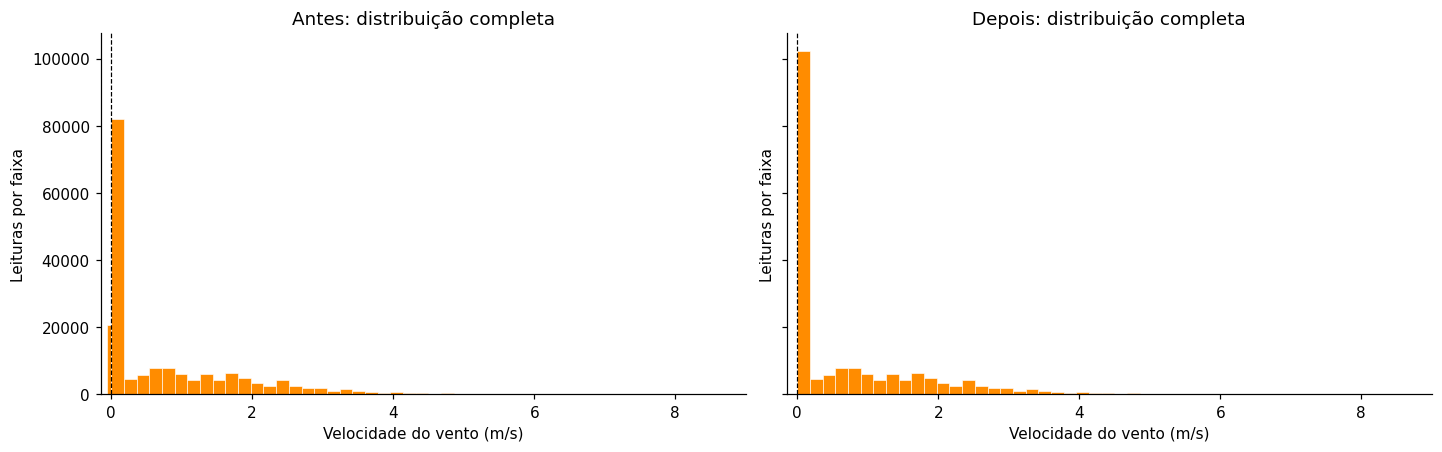

In [11]:
# A primeira faixa termina em zero: os negativos não se misturam com os zeros no histograma.
bins = np.r_[[-0.06, 0.0], np.arange(0.18, 9.01, 0.18)]
fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharex=True, sharey=True, layout="constrained")
for ax, frame, title in zip(
    axes,
    [weather_before_wind, weather],
    ["Antes: distribuição completa", "Depois: distribuição completa"],
):
    ax.hist(
        frame["wind_speed"].dropna(),
        bins=bins,
        color="darkorange",
        edgecolor="white",
        linewidth=0.4,
    )
    ax.axvline(0, color="black", linestyle="--", linewidth=0.8)
    ax.set(
        title=title,
        xlabel="Velocidade do vento (m/s)",
        ylabel="Leituras por faixa",
        xlim=(-0.15, 9),
    )
fig.savefig(FIGURES_DIR / "01_vento_antes_depois.png", bbox_inches="tight")
plt.show()

In [12]:
wind_check = pd.DataFrame(
    [
        {
            "etapa": label,
            "linhas": len(frame),
            "negativos": int(frame["wind_speed"].lt(0).sum()),
            "zeros": int(frame["wind_speed"].eq(0).sum()),
            "positivos": int(frame["wind_speed"].gt(0).sum()),
            "zeros_pct": frame["wind_speed"].eq(0).mean() * 100,
            "nulos": int(frame["wind_speed"].isna().sum()),
        }
        for label, frame in [("Antes", weather_before_wind), ("Depois", weather)]
    ]
)
wind_check["demais_colunas_preservadas"] = weather.drop(columns="wind_speed").equals(
    weather_before_wind.drop(columns="wind_speed")
)
display(wind_check.round(2))

,etapa,linhas,negativos,zeros,positivos,zeros_pct,nulos,demais_colunas_preservadas
0,Antes,182129,20513,71241,90375,39.12,0,True
1,Depois,182129,0,91754,90375,50.38,0,True


**Conferência:** as 20.513 correções elevam os zeros de 71.241 (39,12%) para 91.754 (50,38%).
As 90.375 leituras positivas, o número de linhas e os nulos não mudam.
Os positivos vão de 0,01999 a 8,814 m/s, com mediana de aproximadamente 1,254 m/s.


## 4. Cobertura temporal, lacunas e datas de limpeza

Contamos registros em cada dia do calendário, incluindo dias sem dados.
**Contagem diária zero significa ausência de registros; não significa potência medida zero.**
As linhas vermelhas indicam as limpezas informadas para comparar visualmente com as lacunas.


In [13]:
silver_sources = {"inversor": inverter, "meteorologia": weather}
calendar = pd.date_range(
    min(frame["timestamp"].min() for frame in silver_sources.values()).normalize(),
    max(frame["timestamp"].max() for frame in silver_sources.values()).normalize(),
    freq="D",
    name="dia",
)
daily_counts = pd.DataFrame(
    {
        source: frame.groupby(frame["timestamp"].dt.normalize())
        .size()
        .reindex(calendar, fill_value=0)
        for source, frame in silver_sources.items()
    }
)
coverage_summary = pd.DataFrame(
    [
        {
            "fonte": source,
            "inicio": frame["timestamp"].min(),
            "fim": frame["timestamp"].max(),
            "intervalo_mais_frequente": frame["timestamp"].diff().mode().iloc[0],
            "dias_com_registros": int(daily_counts[source].gt(0).sum()),
            "dias_sem_registros_no_calendario": int(daily_counts[source].eq(0).sum()),
        }
        for source, frame in silver_sources.items()
    ]
)
display(coverage_summary)

,fonte,inicio,fim,intervalo_mais_frequente,dias_com_registros,dias_sem_registros_no_calendario
0,inversor,2025-01-01 05:25:00,2026-09-03 11:35:00,0 days 00:05:00,531,107
1,meteorologia,2025-01-01 00:00:00,2026-09-30 23:55:00,0 days 00:05:00,636,2


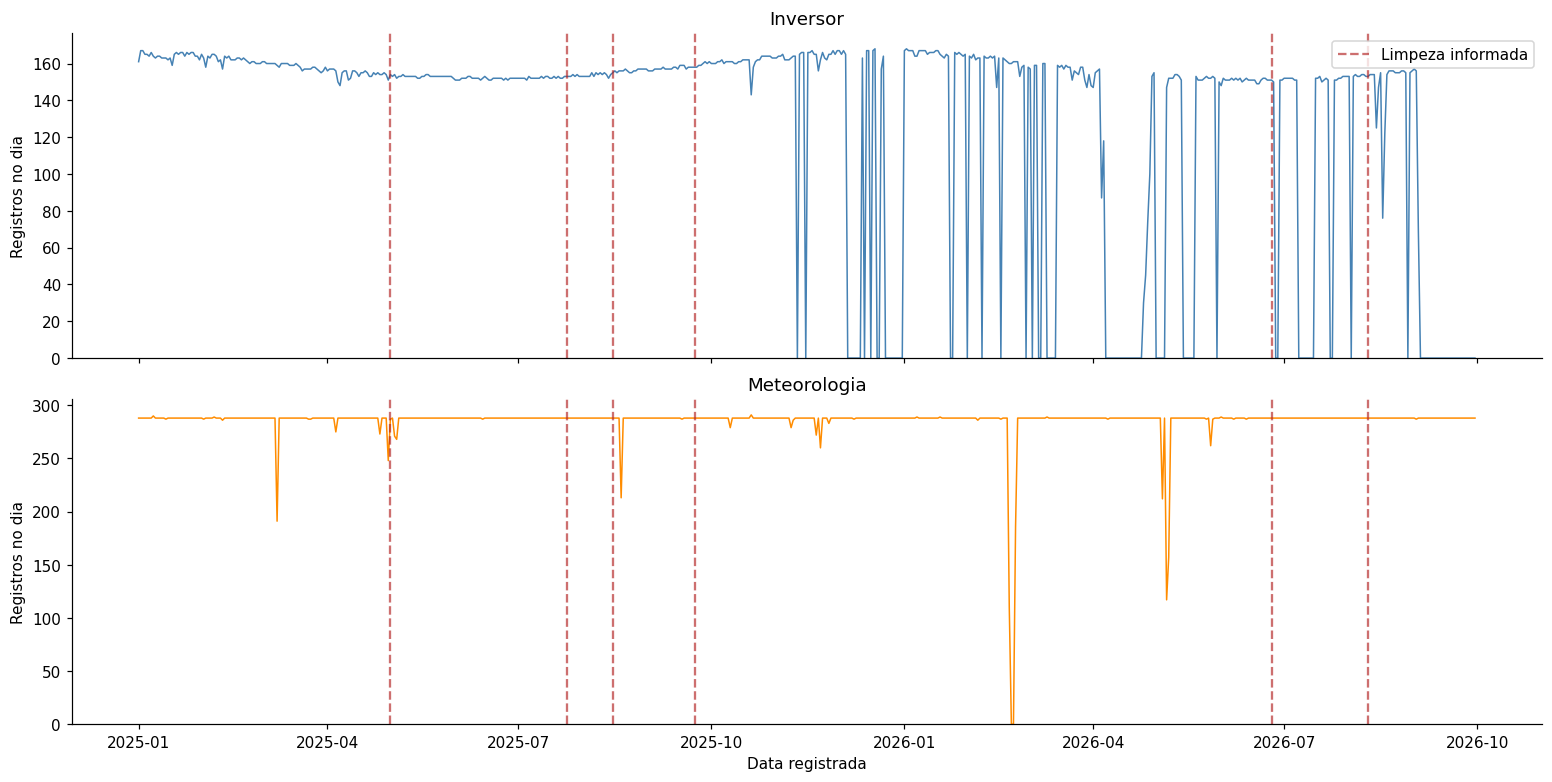

In [14]:
cleaning_dates = pd.to_datetime(
    [
        "2025-05-01",
        "2025-07-24",
        "2025-08-15",
        "2025-09-23",
        "2026-06-25",
        "2026-08-10",
        "2026-10-03",
    ]
)
cleanings_in_history = cleaning_dates[
    (cleaning_dates >= calendar.min()) & (cleaning_dates <= calendar.max())
]
fig, axes = plt.subplots(2, 1, figsize=(14, 7), sharex=True, layout="constrained")
for ax, source, color in zip(axes, ["inversor", "meteorologia"], ["steelblue", "darkorange"]):
    ax.plot(daily_counts.index, daily_counts[source], color=color, linewidth=1)
    for position, event in enumerate(cleanings_in_history):
        ax.axvline(
            event,
            color="firebrick",
            linestyle="--",
            alpha=0.65,
            label="Limpeza informada" if position == 0 else None,
        )
    ax.set(title=source.capitalize(), ylabel="Registros no dia", ylim=(0, None))
    if ax is axes[0]:
        ax.legend(loc="upper right")
axes[-1].set_xlabel("Data registrada")
fig.savefig(FIGURES_DIR / "04_cobertura_diaria.png", bbox_inches="tight")
plt.show()

In [15]:
# Outubro integra o calendário de eventos, mas está fora do histórico recebido.
cleaning_day_counts = daily_counts.reindex(cleaning_dates, fill_value=0).rename_axis(
    "data_limpeza"
)
cleaning_day_counts["dentro_do_historico"] = cleaning_day_counts.index.isin(calendar)
display(cleaning_day_counts.reset_index())

,data_limpeza,inversor,meteorologia,dentro_do_historico
0,2025-05-01,154,287,True
1,2025-07-24,153,288,True
2,2025-08-15,155,288,True
3,2025-09-23,158,288,True
4,2026-06-25,151,288,True
5,2026-08-10,153,288,True
6,2026-10-03,0,0,False


**O que vimos e decidimos:** a frequência predominante é de cinco minutos, com lacunas.
Não interpolamos nem estendemos leituras para preencher dias sem dados. Os maiores intervalos
entre registros aparecem na tabela seguinte; no inversor, o intervalo entre noite e manhã
também faz parte do padrão de coleta e não comprova uma falha de operação.

As datas de limpeza contextualizam a cobertura. O evento de outubro não possui observações
no histórico recebido. As janelas pós-limpeza serão construídas no notebook 02.


In [16]:
gap_parts = []
for source, frame in silver_sources.items():
    times = frame["timestamp"].reset_index(drop=True)
    gaps = pd.DataFrame(
        {
            "fonte": source,
            "registro_anterior": times.shift(),
            "registro_seguinte": times,
            "intervalo": times.diff(),
        }
    )
    gap_parts.append(gaps.nlargest(4, "intervalo"))
largest_gaps = pd.concat(gap_parts, ignore_index=True)
display(largest_gaps)

,fonte,registro_anterior,registro_seguinte,intervalo
0,inversor,2026-04-06 15:45:00,2026-04-25 13:05:00,18 days 21:20:00
1,inversor,2025-12-22 19:00:00,2026-01-01 05:25:00,9 days 10:25:00
2,inversor,2026-07-07 18:40:00,2026-07-16 06:10:00,8 days 11:30:00
3,inversor,2025-12-04 19:00:00,2025-12-12 05:30:00,7 days 10:30:00
4,meteorologia,2026-02-20 09:05:00,2026-02-23 08:30:00,2 days 23:25:00
5,meteorologia,2026-05-06 09:40:00,2026-05-07 10:55:00,1 days 01:15:00
6,meteorologia,2025-03-08 09:05:00,2025-03-08 17:15:00,0 days 08:10:00
7,meteorologia,2025-08-19 08:40:00,2025-08-19 15:00:00,0 days 06:20:00


In [17]:
# Exemplo junto à limpeza de junho: dias sem inversor, com meteorologia disponível.
post_june = daily_counts.loc["2026-06-26":"2026-07-25"]
display(post_june.loc[post_june["inversor"].eq(0)].reset_index())

,dia,inversor,meteorologia
0,2026-06-27,0,288
1,2026-06-28,0,288
2,2026-07-08,0,288
3,2026-07-09,0,288
4,2026-07-10,0,288
5,2026-07-11,0,288
6,2026-07-12,0,288
7,2026-07-13,0,288
8,2026-07-14,0,288
9,2026-07-15,0,288


**Conferência:** nos 30 dias após a limpeza de 25/06/2026, faltam 12 dias de inversor
(27–28/06, 08–15/07 e 23–24/07), enquanto a meteorologia tem 288 leituras em cada um deles.
Uma ausência de dados permanece uma ausência; não a transformamos em geração zero.


## 5. Entrega da silver

Entregamos **82.804 linhas × 15 colunas** do inversor e **182.129 × 5** da meteorologia.
São as fontes separadas, ordenadas e na resolução de origem, sem filtros de linhas,
agregação, pareamento ou imputação. A única mudança em valores medidos é a regra do vento.

Parquet preserva datas e tipos numéricos. Os metadados registram esquema, unidades,
colunas removidas e contagens da correção.


In [18]:
# Conferências finais e gravação das mesmas tabelas usadas neste notebook.
datasets = {}
for source, frame in silver_sources.items():
    filename = "inverter.parquet" if source == "inversor" else "weather.parquet"
    frame.to_parquet(SILVER_DIR / filename, index=False)
    datasets[source] = {
        "file": filename,
        "rows": len(frame),
        "columns": frame.columns.tolist(),
        "dtypes": frame.dtypes.astype(str).to_dict(),
        "start": str(frame["timestamp"].min()),
        "end": str(frame["timestamp"].max()),
    }

In [19]:
silver_metadata = {
    "layer": "silver",
    "scope": "fontes separadas, com limpeza estrutural e correção dos dois negativos conhecidos do vento",
    "generated_at_utc": datetime.now(UTC).isoformat(),
    "datasets": datasets,
    "rules_applied": [
        "converter timestamp e ordenar; preservar horários registrados",
        "conferir um equipamento por fonte, datas e unicidade",
        "remover colunas 100% nulas, textuais e identificadores, incluindo ps_id",
        "preservar linhas, zeros e medições numéricas parcialmente preenchidas",
        "vento: substituir somente -0.018 e -0.036 por zero",
    ],
    "measurement_corrections": {"wind_speed": wind_audit},
    "row_filters_applied": [],
    "aggregation_applied": False,
    "join_applied": False,
    "removed_columns": removed_columns[["fonte", "coluna", "motivo"]].to_dict("records"),
    "units": {
        "total_active_power": "W, confirmado pelo usuário",
        "ghi": "W/m²",
        "temp_amb": "°C",
        "wind_speed": "m/s, convenção de trabalho",
        "relative_hum": "%, convenção de trabalho",
    },
    "notes": [
        "Fuso não informado nos arquivos; sem conversão.",
        "Causa dos pequenos negativos do vento não confirmada; não se trata de calibração.",
    ],
}
(SILVER_DIR / "metadata.json").write_text(
    json.dumps(silver_metadata, ensure_ascii=False, indent=2), encoding="utf-8"
)

7936

In [20]:
display(
    pd.DataFrame(
        [
            {
                "fonte": source,
                "arquivo": info["file"],
                "linhas": info["rows"],
                "colunas": len(info["columns"]),
                "celulas_nulas": int(silver_sources[source].isna().sum().sum()),
                "arquivo_igual_a_tabela": pd.read_parquet(SILVER_DIR / info["file"]).equals(
                    silver_sources[source]
                ),
            }
            for source, info in datasets.items()
        ]
    )
)

,fonte,arquivo,linhas,colunas,celulas_nulas,arquivo_igual_a_tabela
0,inversor,inverter.parquet,82804,15,0,True
1,meteorologia,weather.parquet,182129,5,0,True


Arquivos: [inversor](../data/silver/inverter.parquet), [meteorologia](../data/silver/weather.parquet)
e [metadados](../data/silver/metadata.json).

Siga para [02 — preparação da gold/ABT](02-gold-abt.ipynb): pareamento, zeros de potência,
GHI, recortes da análise, blocos completos e informações das limpezas.
O [resumo dos tratamentos](../docs/tratamentos_dados.md) reúne as decisões para apresentação.
